In [ ]:
# conda env tabpfn_env

In [ ]:
# # Install sklearn
# ! pip install scikit-learn==1.5.2

# # Install TabPFN API Client
# ! pip install tabpfn-client

# # TabPFN Extensions installs optional functionalities around the TabPFN model
# # These include post-hoc ensembles, interpretability tools, and more
# ! git clone https://github.com/PriorLabs/tabpfn-extensions
# ! pip install -e tabpfn-extensions
# ! pip install tabpfn # TabPFN, currently required by tabpfn-extensions, but not basic usage


# # Install Baselines
# ! pip install catboost xgboost

# # Install example datasets
# ! pip install datasets

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from tabpfn import TabPFNRegressor
from sklearn.preprocessing import StandardScaler

In [2]:
# Load dataset
df = pd.read_csv("./Final_DataPoints_With_DC.csv")

In [3]:
pd.DataFrame(df).head()

,w1,w2,w3,wPL,DC,range
0,0.19,0.63,0.94,0.000029,NEDC_extended,168.577083
1,0.28,0.88,0.44,0.000028,NEDC_extended,168.577083
2,0.43,0.69,0.95,0.000073,FHDS_extended,193.161944
3,0.62,0.12,0.12,0.000062,US06HW_extended,125.559007
4,0.99,0.08,0.25,0.000036,US06City_extended,154.212260


In [4]:
X = df[['w1', 'w2', 'w3', 'wPL', 'DC']].values
y = df['range'].values

X

array([[0.19, 0.63, 0.94, 2.9e-05, 'NEDC_extended'],
       [0.28, 0.88, 0.44, 2.8e-05, 'NEDC_extended'],
       [0.43, 0.69, 0.95, 7.3e-05, 'FHDS_extended'],
       ...,
       [0.75, 0.13, 0.82, 8e-05, 'US06City_extended'],
       [0.52, 0.3, 0.7, 6.7e-05, 'FUDS_extended'],
       [0.06, 0.87, 0.63, 4.4e-05, 'US06City_extended']],
      shape=(2800, 5), dtype=object)

In [5]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,NEDC_extended
1,0.28,0.88,0.44,0.000028,NEDC_extended
2,0.43,0.69,0.95,0.000073,FHDS_extended
3,0.62,0.12,0.12,0.000062,US06HW_extended
4,0.99,0.08,0.25,0.000036,US06City_extended


In [6]:
# extracting 4th column from X

pd.DataFrame(X[:, 4]).head()

,0
0,NEDC_extended
1,NEDC_extended
2,FHDS_extended
3,US06HW_extended
4,US06City_extended


In [7]:
# encoding the 4th column

X[:, 4] = pd.Categorical(X[:, 4]).codes

In [8]:
pd.Series(X[:, 4]).value_counts()

3    400
0    400
5    400
4    400
2    400
6    400
1    400
Name: count, dtype: int64

In [9]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,3
1,0.28,0.88,0.44,0.000028,3
2,0.43,0.69,0.95,0.000073,0
3,0.62,0.12,0.12,0.000062,5
4,0.99,0.08,0.25,0.000036,4


In [10]:
# size of the dataset

X.shape

(2800, 5)

In [11]:
# comparing the original and encoded values and making a df which contains the original and encoded values for each unique value

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates()

# make a CSV for this DF which is printed

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates().to_csv('Encoded_DC.csv', index=False)


In [12]:
X.shape

(2800, 5)

In [13]:
# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
model = TabPFNRegressor()

In [15]:
# Fit the model on the training data
model.fit(X_train, y_train)

TabPFNRegressor()

In [16]:
# Predict on both training and testing sets
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [17]:
# Evaluate model performance using RMSE and R²
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)

In [18]:
print("Training RMSE: {:.2f}".format(train_rmse))
print("Test RMSE: {:.2f}".format(test_rmse))
print("Training R²: {:.2f}".format(train_r2))
print("Test R²: {:.2f}".format(test_r2))

Training RMSE: 14.47
Test RMSE: 15.69
Training R²: 0.65
Test R²: 0.62


In [20]:
# Example prediction using the first row of the dataset
example_input = X[0:1]
example_prediction = model.predict(example_input)
print("\nExample prediction:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Example prediction:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.63
Actual range: 168.58


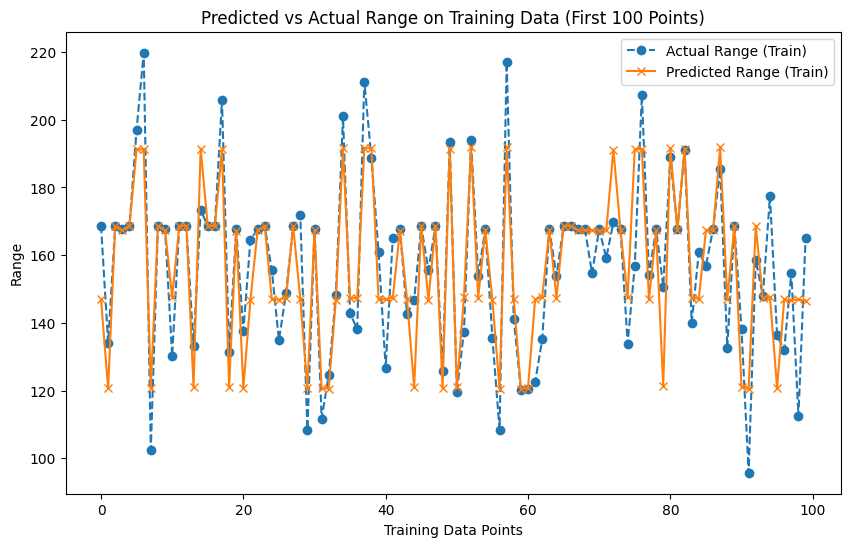

In [29]:
# Plot predicted vs. actual values for the first 100 training data points
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

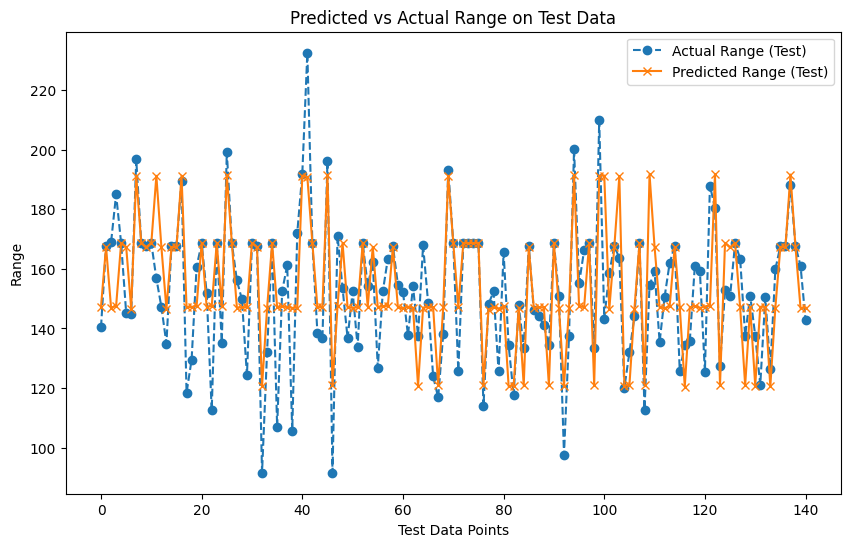

In [30]:
# Plot predicted vs. actual values for test data
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds, label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data')
plt.legend()
plt.show()

In [42]:
dc_categories = pd.Categorical(df['DC']).categories

In [109]:
def predict_range(w1, w2, w3, wPL, DC):

    input_sample = np.array([[w1, w2, w3, wPL, DC]])
    # Predict using the trained TabPFN regressor.
    prediction = model.predict(input_sample)
    return prediction[0]

In [43]:
# -------------------------------
# Test the predict_range function with the first row of the dataset
# -------------------------------
example_input = X[0:1]  # First row (already encoded)
example_prediction = model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct example prediction from model:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.66
Actual range: 168.58


In [46]:
raw_DC_value = df['DC'].iloc[0]
pred_from_func = predict_range(
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)
print("\nExample prediction using predict_range function:")
print("Predicted range: {:.2f}".format(pred_from_func))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Example prediction using predict_range function:
Predicted range: 168.66
Actual range: 168.58


In [47]:
import pickle

In [49]:
# -------------------------------
# Save the trained model using pickle
# -------------------------------
with open("./Models/tabpfn_regressor_local.pkl", "wb") as f:
    pickle.dump(model, f)
print("Model saved to tabpfn_regressor_local.pkl")

Model saved to tabpfn_regressor_local.pkl


In [50]:
# -------------------------------
# Load the model from disk
# -------------------------------
with open("./Models/tabpfn_regressor_local.pkl", "rb") as f:
    loaded_model = pickle.load(f)
print("Model loaded from tabpfn_regressor_local.pkl")

Model loaded from tabpfn_regressor_local.pkl


In [51]:
example_prediction = loaded_model.predict(example_input)
print("\nDirect example prediction from model:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct example prediction from model:
Input features:
 [[0.19 0.63 0.94 2.9e-05 3]]
Predicted range: 168.66
Actual range: 168.58


In [52]:
# Evaluate the loaded model on the test set to verify it works the same
loaded_test_preds = loaded_model.predict(X_test)
loaded_test_rmse = np.sqrt(mean_squared_error(y_test, loaded_test_preds))
loaded_test_r2   = r2_score(y_test, loaded_test_preds)

print("Loaded Model Test RMSE: {:.2f}".format(loaded_test_rmse))
print("Loaded Model Test R²: {:.2f}".format(loaded_test_r2))


Loaded Model Test RMSE: 15.46
Loaded Model Test R²: 0.56


In [53]:
def predict_range_model(model_instance, w1, w2, w3, wPL, DC):
    """
    Predict the range for a single new sample.
    The DC value is encoded using the original dataset's unique categories.
    """
    # Encode the provided DC value to its corresponding numeric code
    dc_code = pd.Categorical([DC], categories=dc_categories).codes[0]
    # Create a 2D array for the new sample
    input_sample = np.array([[w1, w2, w3, wPL, dc_code]])
    # Use the provided model instance to predict
    prediction = model_instance.predict(input_sample)
    return prediction[0]

In [90]:
example_input = X[0:1]  # Already encoded sample from the original dataset
raw_DC_value = df['DC'].iloc[0]  # Original DC value

print(example_input, raw_DC_value)

[[0.19 0.63 0.94 2.9e-05 3]] NEDC_extended


In [55]:
# Direct prediction from the loaded model for comparison
direct_prediction = loaded_model.predict(example_input)[0]

In [56]:
# Prediction using our helper function
func_prediction = predict_range_model(
    loaded_model,
    float(example_input[0][0]),
    float(example_input[0][1]),
    float(example_input[0][2]),
    float(example_input[0][3]),
    raw_DC_value
)

In [57]:
print("\nDirect prediction from loaded model:")
print("Predicted range: {:.2f}".format(direct_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Direct prediction from loaded model:
Predicted range: 168.66
Actual range: 168.58


In [58]:
print("\nPrediction using predict_range_model function:")
print("Predicted range: {:.2f}".format(func_prediction))
print("Actual range: {:.2f}".format(df['range'].iloc[0]))


Prediction using predict_range_model function:
Predicted range: 168.66
Actual range: 168.58


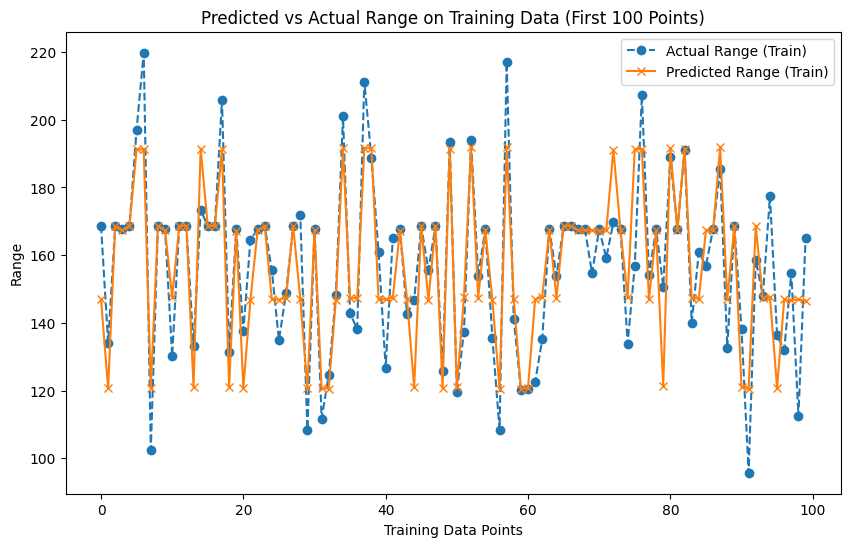

In [59]:
# -------------------------------
# Plot predicted vs. actual values for training data (first 100 points)
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_train[:100], label='Actual Range (Train)', marker='o', linestyle='--')
plt.plot(train_preds[:100], label='Predicted Range (Train)', marker='x', linestyle='-')
plt.xlabel('Training Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Training Data (First 100 Points)')
plt.legend()
plt.show()

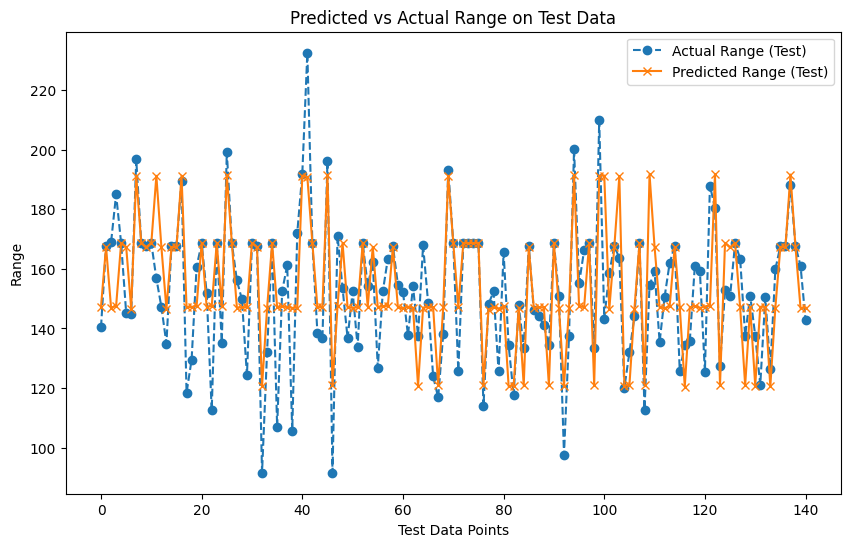

In [61]:
# -------------------------------
# Plot predicted vs. actual values for test data
# -------------------------------
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='Actual Range (Test)', marker='o', linestyle='--')
plt.plot(test_preds, label='Predicted Range (Test)', marker='x', linestyle='-')
plt.xlabel('Test Data Points')
plt.ylabel('Range')
plt.title('Predicted vs Actual Range on Test Data')
plt.legend()
plt.show()

In [122]:
# Example prediction using the first row of the dataset
example_input = [[1.0, 0, 0, 9.989717684640782e-05, 6]]
example_prediction = model.predict(example_input)
print("\nExample prediction:")
print("Input features:\n", example_input)
print("Predicted range: {:.2f}".format(example_prediction[0]))


Example prediction:
Input features:
 [[1.0, 0, 0, 9.989717684640782e-05, 6]]
Predicted range: 147.33


In [117]:
# Original values
w1 = 0.001397731107556144
w2 = 0.9997720987738381
w3 = 0.005139596486616328
wPL = 9.989717684640782e-05
DC = 1

# Round w1, w2, and w3 to 2 decimal places
w1 = round(w1, 2)
w2 = round(w2, 2)
w3 = round(w3, 2)

predicted_range = predict_range(w1, w2, w3, wPL, DC)
# printing input values
print("Input values:")
print("w1:", w1, "w2:", w2, "w3:", w3, "wPL:", wPL, "DC:", DC)
print("Predicted range:", predicted_range)

Input values:
w1: 0.0 w2: 1.0 w3: 0.01 wPL: 9.989717684640782e-05 DC: 1
Predicted range: 167.22855


In [65]:
from skopt import gp_minimize
from skopt.space import Real
from skopt.callbacks import DeltaYStopper
from skopt.utils import use_named_args
from functools import partial

In [81]:
# Define the search space for x1, x2, x3, and x4
space = [
    Real(0.0, 1.0, name='x1'),
    Real(0.0, 1.0, name='x2'),
    Real(0.0, 1.0, name='x3'),
    Real(0.0, 0.0001, name='x4')
]

# Define the objective function for minimization
def objective_function(params, x5):
    x1, x2, x3, x4 = params
    x1 = round(x1, 2)
    x2 = round(x2, 2)
    x3 = round(x3, 2)
    x4 = round(x4, 8)
    return -predict_range(x1, x2, x3, x4, x5)

# Callback function to print progress
def print_progress(res):
    iteration = len(res.func_vals)
    current_best = -min(res.func_vals)
    current_params = res.x_iters[-1]
    print(f"Iteration {iteration}: Current best predicted range = {current_best:.2f}, Latest params = {current_params}")

# Create a DeltaYStopper callback: if the best objective doesn't improve by at least 0.001
# over the last 10 iterations, stop the optimization.
delta_stopper = DeltaYStopper(delta=0.001, n_best=10)

# Dictionary to store optimal results for each x5 value
optimal_results = {}

In [ ]:
for x5_value in range(7):  # x5 values from 0 to 6
    print(f"\nOptimizing for x5 = {x5_value}...")
    fixed_obj = partial(objective_function, x5=x5_value)
    
    result = gp_minimize(
        fixed_obj,
        space,
        n_calls=300,
        n_initial_points=20,
        acq_func='EI',
        random_state=42,
        callback=[print_progress, delta_stopper]
    )
    
    best_x1, best_x2, best_x3, best_x4 = result.x
    optimal_range = -result.fun  # reverse sign for maximization
    
    optimal_results[x5_value] = {
        "x1": round(best_x1, 2),
        "x2": round(best_x2, 2),
        "x3": round(best_x3, 2),
        "x4": round(best_x4, 6),
        "optimal_range": round(optimal_range, 2)
    }

for x5_value, results in optimal_results.items():
    print(f"\nFor x5 = {x5_value}:")
    print(f"  Optimal inputs: x1 = {results['x1']:.2f}, x2 = {results['x2']:.2f}, x3 = {results['x3']:.2f}, x4 = {results['x4']:.6f}")
    print(f"  Maximum predicted range: {results['optimal_range']:.2f}")

In [ ]:
# saving optimal range and weights to a CSV file

for x5_value, results in optimal_results.items():
    pd.DataFrame({
        'w1': [results['x1']], 
        'w2': [results['x2']], 
        'w3': [results['x3']], 
        'wPL': [f"{results['x4']}"], 
        'DC': [x5_value], 
        'DC_Name': [dc_categories[x5_value]],
        'Range': [results['optimal_range']]
    }).to_csv('Optimised_Bayesian_Values_Range.csv', mode='a', header=False, index=False)
